In [2]:
import os
import awkward as ak
import matplotlib.pyplot as plt
import mplhep as hep
hep.style.use("CMS")

In [3]:
base_folder = "/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval"
folders = [
    "photon_stdCalo_E20to200_closeBy_n2_d0p5cm_ticlv6_rep8_split",
    "photon_stdCalo_E20to200_closeBy_n2_d1cm_ticlv6_rep8_split",
    "photon_stdCalo_E20to200_closeBy_n2_d3cm_ticlv6_rep8_split",
    "photon_stdCalo_E20to200_closeBy_n2_d10cm_ticlv6_rep8_split",
    "photon_stdCalo_E20to200_closeBy_n2_d2cm_ticlv6_rep8_split",
    "photon_stdCalo_E20to200_closeBy_n2_d5cm_ticlv6_rep8_split"
]

def get_distance_from_folder(folder_name):
    # Extract the distance value from the folder name
    parts = folder_name.split('_')
    for part in parts:
        if part.startswith('d'):
            if "p" in part:
                return float(part[1:].replace('p', '.').replace('cm', ''))  # Convert 'd0p5cm' to 0.5
            else:
                return float(part[1:-2])  # Remove 'd' and 'cm'
    return None

files = {
    get_distance_from_folder(folder): [f"{base_folder}/{folder}/{f}" for f in os.listdir(os.path.join(base_folder, folder)) if f.endswith('.parquet')][0] for folder in folders
}
#filename = "/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval/photon_stdCalo_E20to200_closeBy_n2_d2cm_ticlv6_rep8_split/best-epoch=031-val_loss=15.68618__test_photon_stdCalo_E20to200_closeBy_n2_d2cm_ticlv6_rep8_split.parquet"
#df = ak.from_parquet(filename)
#df.fields
files

{0.5: '/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval/photon_stdCalo_E20to200_closeBy_n2_d0p5cm_ticlv6_rep8_split/best-epoch=031-val_loss=15.68618__test_photon_stdCalo_E20to200_closeBy_n2_d0p5cm_ticlv6_rep8_split.parquet',
 1.0: '/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval/photon_stdCalo_E20to200_closeBy_n2_d1cm_ticlv6_rep8_split/best-epoch=031-val_loss=15.68618__test_photon_stdCalo_E20to200_closeBy_n2_d1cm_ticlv6_rep8_split.parquet',
 3.0: '/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval/photon_stdCalo_E20to200_closeBy_n2_d3cm_ticlv6_rep8_split/best-epoch=031-val_loss=15.68618__test_photon_stdCalo_E20to200_closeBy_n2_d3cm_ticlv6_rep8_split.parquet',
 10.0: '/home/mmarcheg/work/ml4reco/hgcal_reco_studies/data/hgcal_v2_layercluster_truthCaloBoundary_20261117-T234054/eval/photon_stdCalo_E

In [4]:
df.TruthCB.fields

NameError: name 'df' is not defined

In [ ]:
df.TruthCB.TruthCB_pred_e

<Array [[86.6, 174], [140, ... 138], [29, 103]] type='500 * var * float32'>

{0.5: {'MaskFormer': 0.0, 'TICL': 0.338},
 1.0: {'MaskFormer': 0.0, 'TICL': 0.36},
 3.0: {'MaskFormer': 0.0, 'TICL': 0.0},
 10.0: {'MaskFormer': 0.0, 'TICL': 0.0},
 2.0: {'MaskFormer': 0.0, 'TICL': 0.072},
 5.0: {'MaskFormer': 0.0, 'TICL': 0.0}}

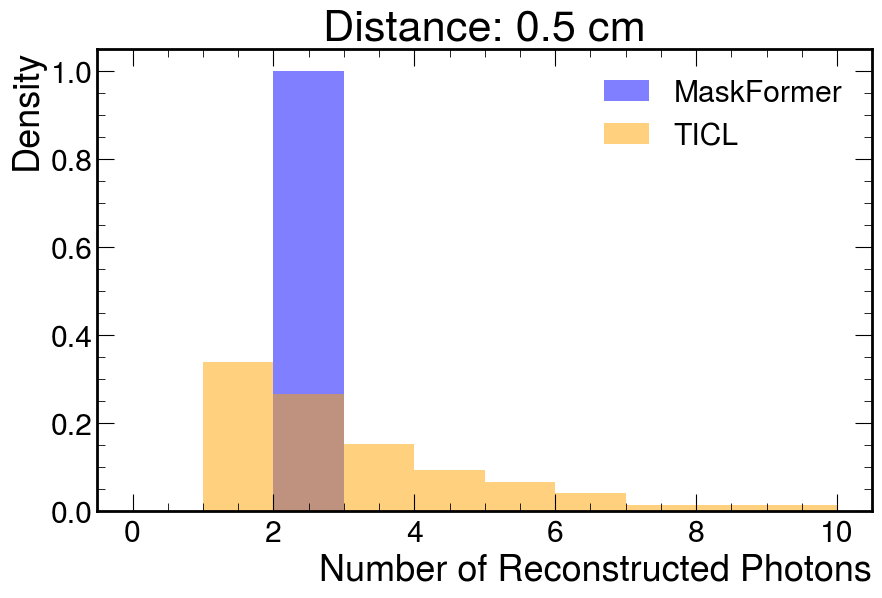

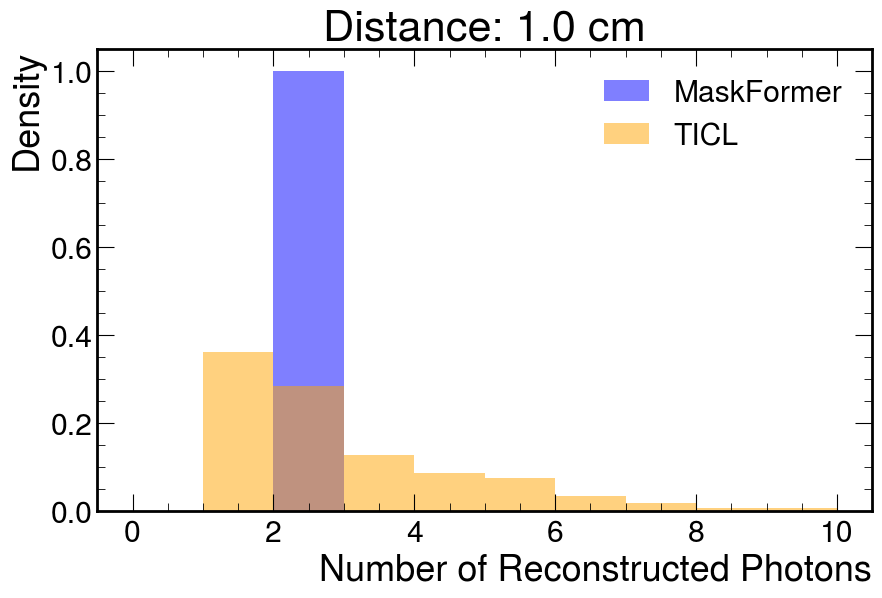

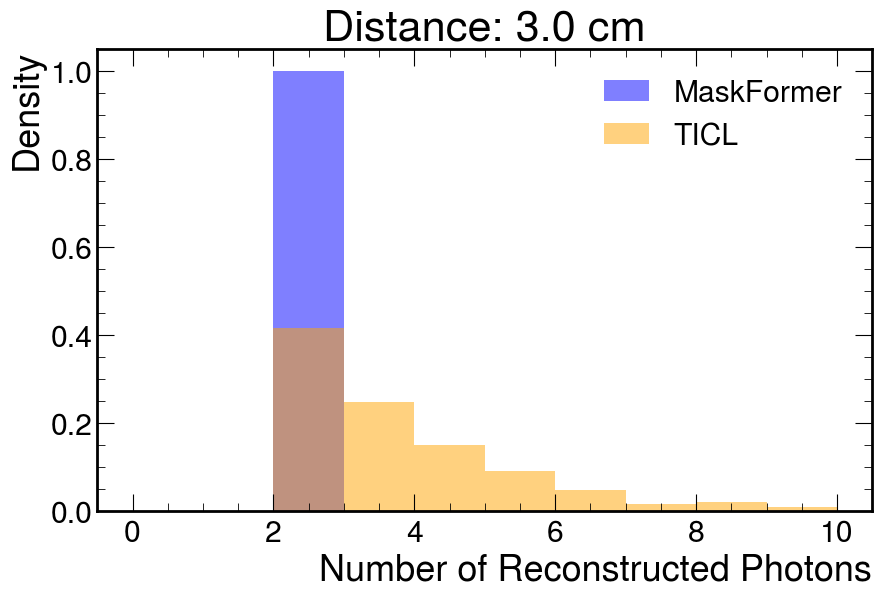

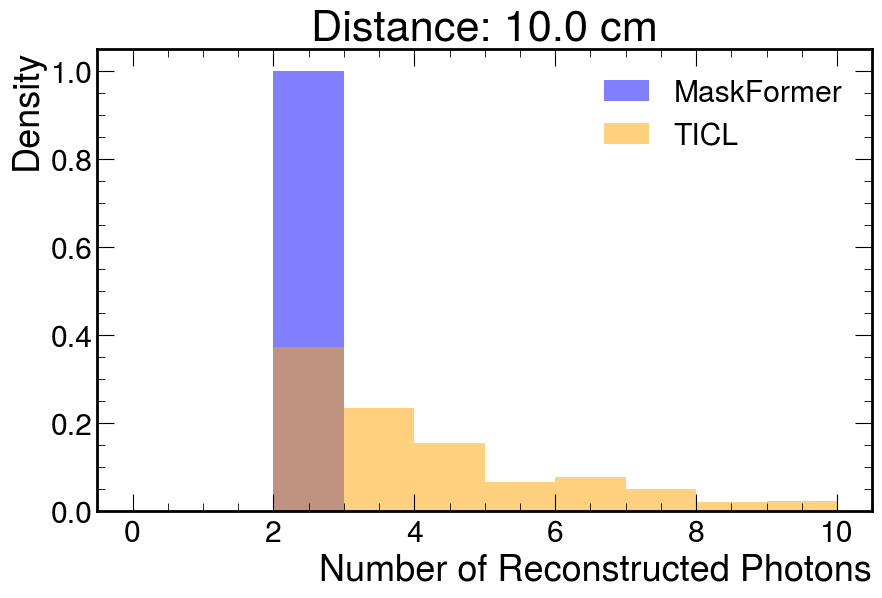

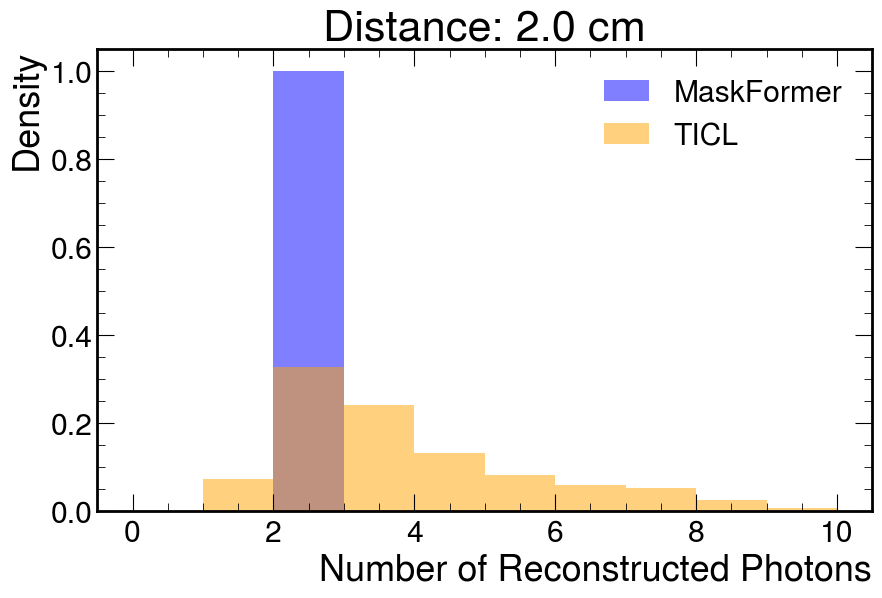

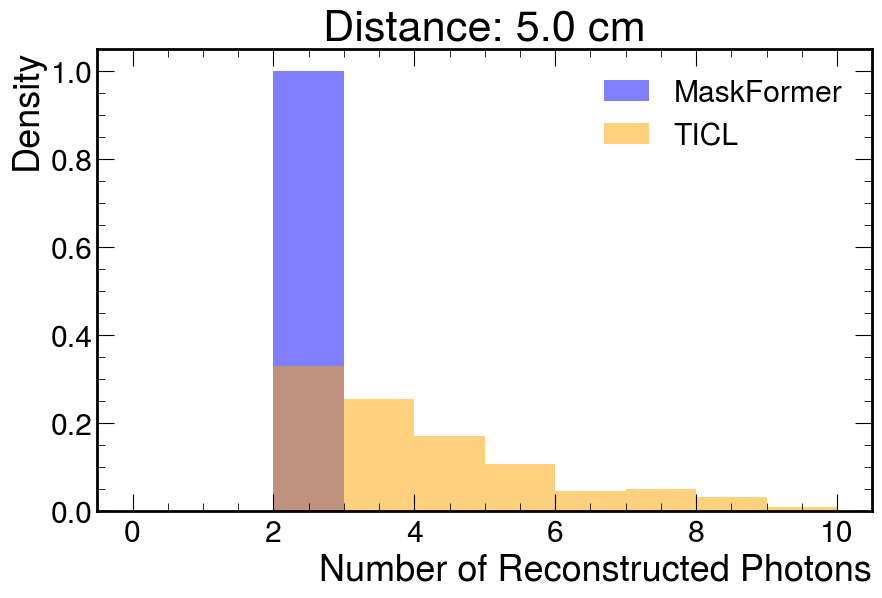

In [ ]:
nmean = {distance: {} for distance in files.keys()}
nsingle = {distance: {} for distance in files.keys()}
for distance, filename in files.items():
    df = ak.from_parquet(filename)
    nmaskformer = ak.num(df.TruthCB.TruthCB_pred_e)
    nticl = ak.num(df.ticlTrackstersCLUEstering.ticlTrackstersCLUEstering_raw_energy)

    nmean[distance]['MaskFormer'] = ak.mean(nmaskformer)
    nmean[distance]['TICL'] = ak.mean(nticl)

    nsingle[distance]['MaskFormer'] = ak.sum(nmaskformer == 1)
    nsingle[distance]['TICL'] = ak.sum(nticl == 1)

    plt.figure(figsize=(10, 6))
    plt.hist(nmaskformer, bins=10, range=(0, 10), alpha=0.5, label='MaskFormer', color='blue', density=True)
    plt.hist(nticl, bins=10, range=(0, 10), alpha=0.5, label='TICL', color='orange', density=True)
    plt.xlabel('Number of Reconstructed Photons')
    plt.ylabel('Density')
    plt.title('Distance: {} cm'.format(distance))
    plt.legend()

frac_single = {distance: {"MaskFormer": nsingle[distance]['MaskFormer'] / len(df), "TICL": nsingle[distance]['TICL'] / len(df)} for distance in files.keys()}
frac_single

{0.5: {'MaskFormer': 2.0, 'TICL': 2.658},
 1.0: {'MaskFormer': 2.0, 'TICL': 2.5},
 3.0: {'MaskFormer': 2.0, 'TICL': 3.336},
 10.0: {'MaskFormer': 2.0, 'TICL': 3.616},
 2.0: {'MaskFormer': 2.0, 'TICL': 3.396},
 5.0: {'MaskFormer': 2.0, 'TICL': 3.654}}

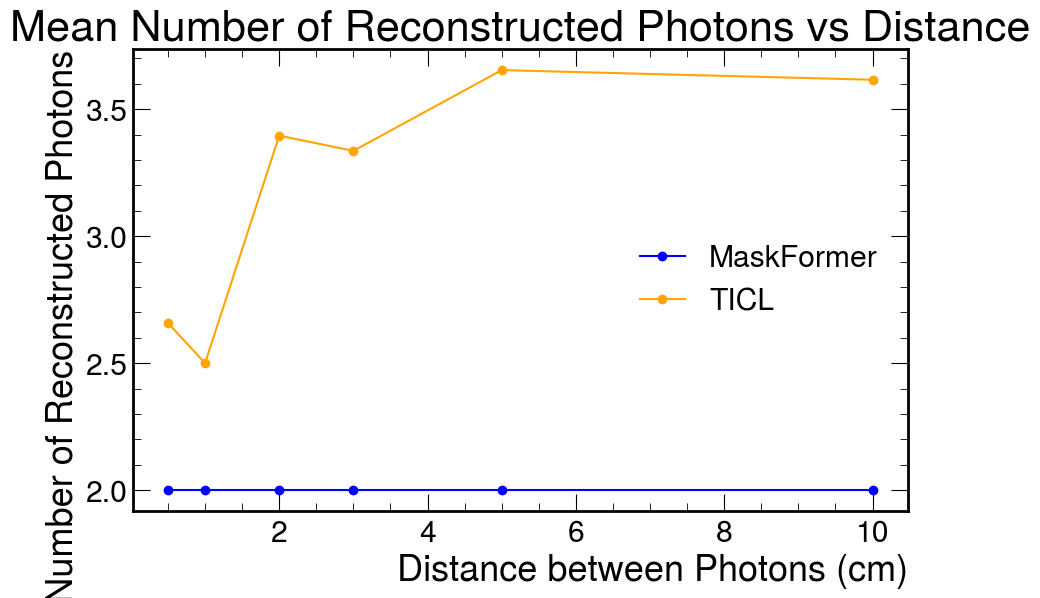

In [ ]:
x = sorted(list(nmean.keys()))
y_maskformer = [nmean[distance]['MaskFormer'] for distance in x]
y_ticl = [nmean[distance]['TICL'] for distance in x]
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(x, y_maskformer, marker='o', label='MaskFormer', color='blue')
ax.plot(x, y_ticl, marker='o', label='TICL', color='orange')
ax.set_xlabel('Distance between Photons (cm)')
ax.set_ylabel('Mean Number of Reconstructed Photons')
ax.set_title('Mean Number of Reconstructed Photons vs Distance')
ax.legend()

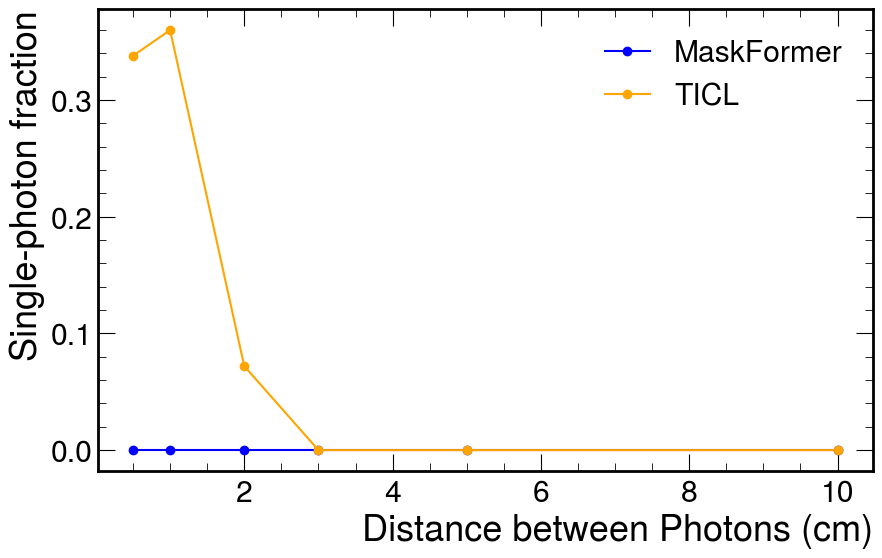

In [ ]:
x = sorted(list(frac_single.keys()))
y_maskformer = [frac_single[distance]['MaskFormer'] for distance in x]
y_ticl = [frac_single[distance]['TICL'] for distance in x]
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(x, y_maskformer, marker='o', label='MaskFormer', color='blue')
ax.plot(x, y_ticl, marker='o', label='TICL', color='orange')
ax.set_xlabel('Distance between Photons (cm)')
ax.set_ylabel('Single-photon fraction')
#ax.set_title('Fraction of events with a single reconstructed photon vs Distance')
ax.legend()

In [ ]:
df.ticlTrackstersCLUEstering.ticlTrackstersCLUEstering_raw_energy.tolist()[:10]

[[199.5955352783203,
  41.30278778076172,
  0.48719459772109985,
  1.8356716632843018,
  0.6979925036430359,
  0.7986591458320618,
  0.6772009134292603],
 [7.924651145935059, 185.58798217773438],
 [34.23667907714844, 229.20323181152344],
 [152.07749938964844, 0.9108131527900696, 1.663848876953125],
 [187.036376953125, 1.2638015747070312, 64.78148651123047],
 [17.252540588378906, 235.65379333496094],
 [63.88334655761719, 189.85435485839844],
 [3.7459726333618164, 174.88694763183594],
 [0.8983344435691833,
  154.738037109375,
  59.11235427856445,
  1.2141053676605225,
  0.5555360913276672,
  0.8427250981330872,
  1.8681484460830688],
 [42.689842224121094, 2.178795576095581, 126.90875244140625]]

In [ ]:
df.TruthCB.TruthCB_pred_e.tolist()[:10]

[[86.64338684082031, 174.39036560058594],
 [139.89349365234375, 28.299386978149414],
 [154.087158203125, 97.61982727050781],
 [125.01434326171875, 36.75992965698242],
 [115.31426239013672, 195.11239624023438],
 [88.73111724853516, 140.35513305664062],
 [102.80120086669922, 170.96987915039062],
 [39.525455474853516, 157.53262329101562],
 [175.61044311523438, 71.35466766357422],
 [98.2663345336914, 80.92335510253906]]

In [ ]:
df.TruthCB.TruthCB_energy.tolist()[:10]

[[110.60333251953125, 189.84193420410156],
 [184.63372802734375, 31.088533401489258],
 [183.9290313720703, 98.80702209472656],
 [168.7048797607422, 40.48788833618164],
 [118.2176284790039, 189.859375],
 [80.85063171386719, 177.35772705078125],
 [96.50208282470703, 175.3918914794922],
 [30.8172607421875, 181.08538818359375],
 [177.92724609375, 71.34750366210938],
 [95.48912048339844, 92.810302734375]]